In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sebastiancolo/task-2/glucose_level.npy
/kaggle/input/datasets/sebastiancolo/task-2/glucose_level_test.npy


In [2]:
# %% ===== 1. IMPORT =====
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization

# Seed per riproducibilità
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
    print('GPU device not found. Go to Runtime > Change runtime type > GPU')
else:
    print('Found GPU at: {}'.format(device_name))

TensorFlow version: 2.20.0
Found GPU at: /device:GPU:0


I0000 00:00:1792670621.674787      49 gpu_device.cc:2020] Created device /device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792670621.678344      49 gpu_device.cc:2020] Created device /device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [3]:
# %% ===== 2. IMPORT DATASET (Kaggle) =====
import glob

def trova_file(nome):
    trovati = glob.glob(f'/kaggle/input/**/{nome}', recursive=True)
    if not trovati:
        raise FileNotFoundError(f"{nome} non trovato in /kaggle/input. Hai aggiunto il dataset come Input?")
    return trovati[0]

Train_set = np.load(trova_file('glucose_level.npy'))
Test_set = np.load(trova_file('glucose_level_test.npy'))
print("Train set shape:", Train_set.shape)
print("Test set shape:", Test_set.shape)

# Colonna 1 = valore di glucosio
Train_set_value = Train_set[:, :, 1]
Test_set_value = Test_set[:, :, 1]

Train set shape: (12, 12641, 2)
Test set shape: (12, 2897, 2)


In [4]:
# %% ===== 3. CLEANING DATASET =====
GLU_MIN, GLU_MAX = 40, 400   # range sensore CGM (mg/dL)
MAX_GAP = 12                 # buchi <= 12 campioni (1 ora) -> interpolati
invalid = {'nan', 'NaN', 'NAN', '', 'None'}

def to_float_with_nan(row):
    out = np.full(len(row), np.nan)
    for j, v in enumerate(row):
        v = str(v).strip()
        if v in invalid:
            continue
        try:
            out[j] = float(v)
        except ValueError:
            pass
    return out

def interpolate_short_gaps(x, max_gap):
    """Interpola linearmente solo i buchi <= max_gap; i più lunghi restano NaN."""
    x = x.copy()
    isn = np.isnan(x)
    n, i, filled = len(x), 0, 0
    while i < n:
        if isn[i]:
            j = i
            while j < n and isn[j]:
                j += 1
            gap = j - i
            if gap <= max_gap and i > 0 and j < n:
                x[i:j] = np.interp(np.arange(i, j), [i - 1, j], [x[i - 1], x[j]])
                filled += gap
            i = j
        else:
            i += 1
    return x, filled

def clean_patient(row):
    x = to_float_with_nan(row)
    with np.errstate(invalid='ignore'):
        x[(x < GLU_MIN) | (x > GLU_MAX)] = np.nan   # include zeri/padding e outlier
    valid = np.where(~np.isnan(x))[0]
    if len(valid) == 0:
        return x[:0], 0, 0
    x = x[valid[0]:valid[-1] + 1]                    # trim NaN iniziali/finali (padding)
    n_missing = int(np.isnan(x).sum())
    x, n_filled = interpolate_short_gaps(x, MAX_GAP)
    return x, n_missing, n_filled

cleaned_Train, cleaned_Test = [], []
print(f"{'Paz':<4} {'Campioni':<9} {'Mancanti':<9} {'Interpolati':<12} {'NaN residui':<11}")
for i in range(12):
    x_tr, miss, fill = clean_patient(Train_set_value[i, :])
    x_te, _, _ = clean_patient(Test_set_value[i, :])
    cleaned_Train.append(x_tr)
    cleaned_Test.append(x_te)
    print(f"{i+1:<4} {len(x_tr):<9} {miss:<9} {fill:<12} {int(np.isnan(x_tr).sum()):<11}")

Paz  Campioni  Mancanti  Interpolati  NaN residui
1    11947     0         0            0          
2    10623     0         0            0          
3    9080      0         0            0          
4    10796     0         0            0          
5    12124     0         0            0          
6    10858     0         0            0          
7    10982     0         0            0          
8    11866     0         0            0          
9    12150     0         0            0          
10   12640     0         0            0          
11   10847     0         0            0          
12   10877     0         0            0          


Paziente 1: 11947 campioni
Paziente 2: 10623 campioni
Paziente 3: 9080 campioni
Paziente 4: 10796 campioni
Paziente 5: 12124 campioni
Paziente 6: 10858 campioni
Paziente 7: 10982 campioni
Paziente 8: 11866 campioni
Paziente 9: 12150 campioni
Paziente 10: 12640 campioni
Paziente 11: 10847 campioni
Paziente 12: 10877 campioni


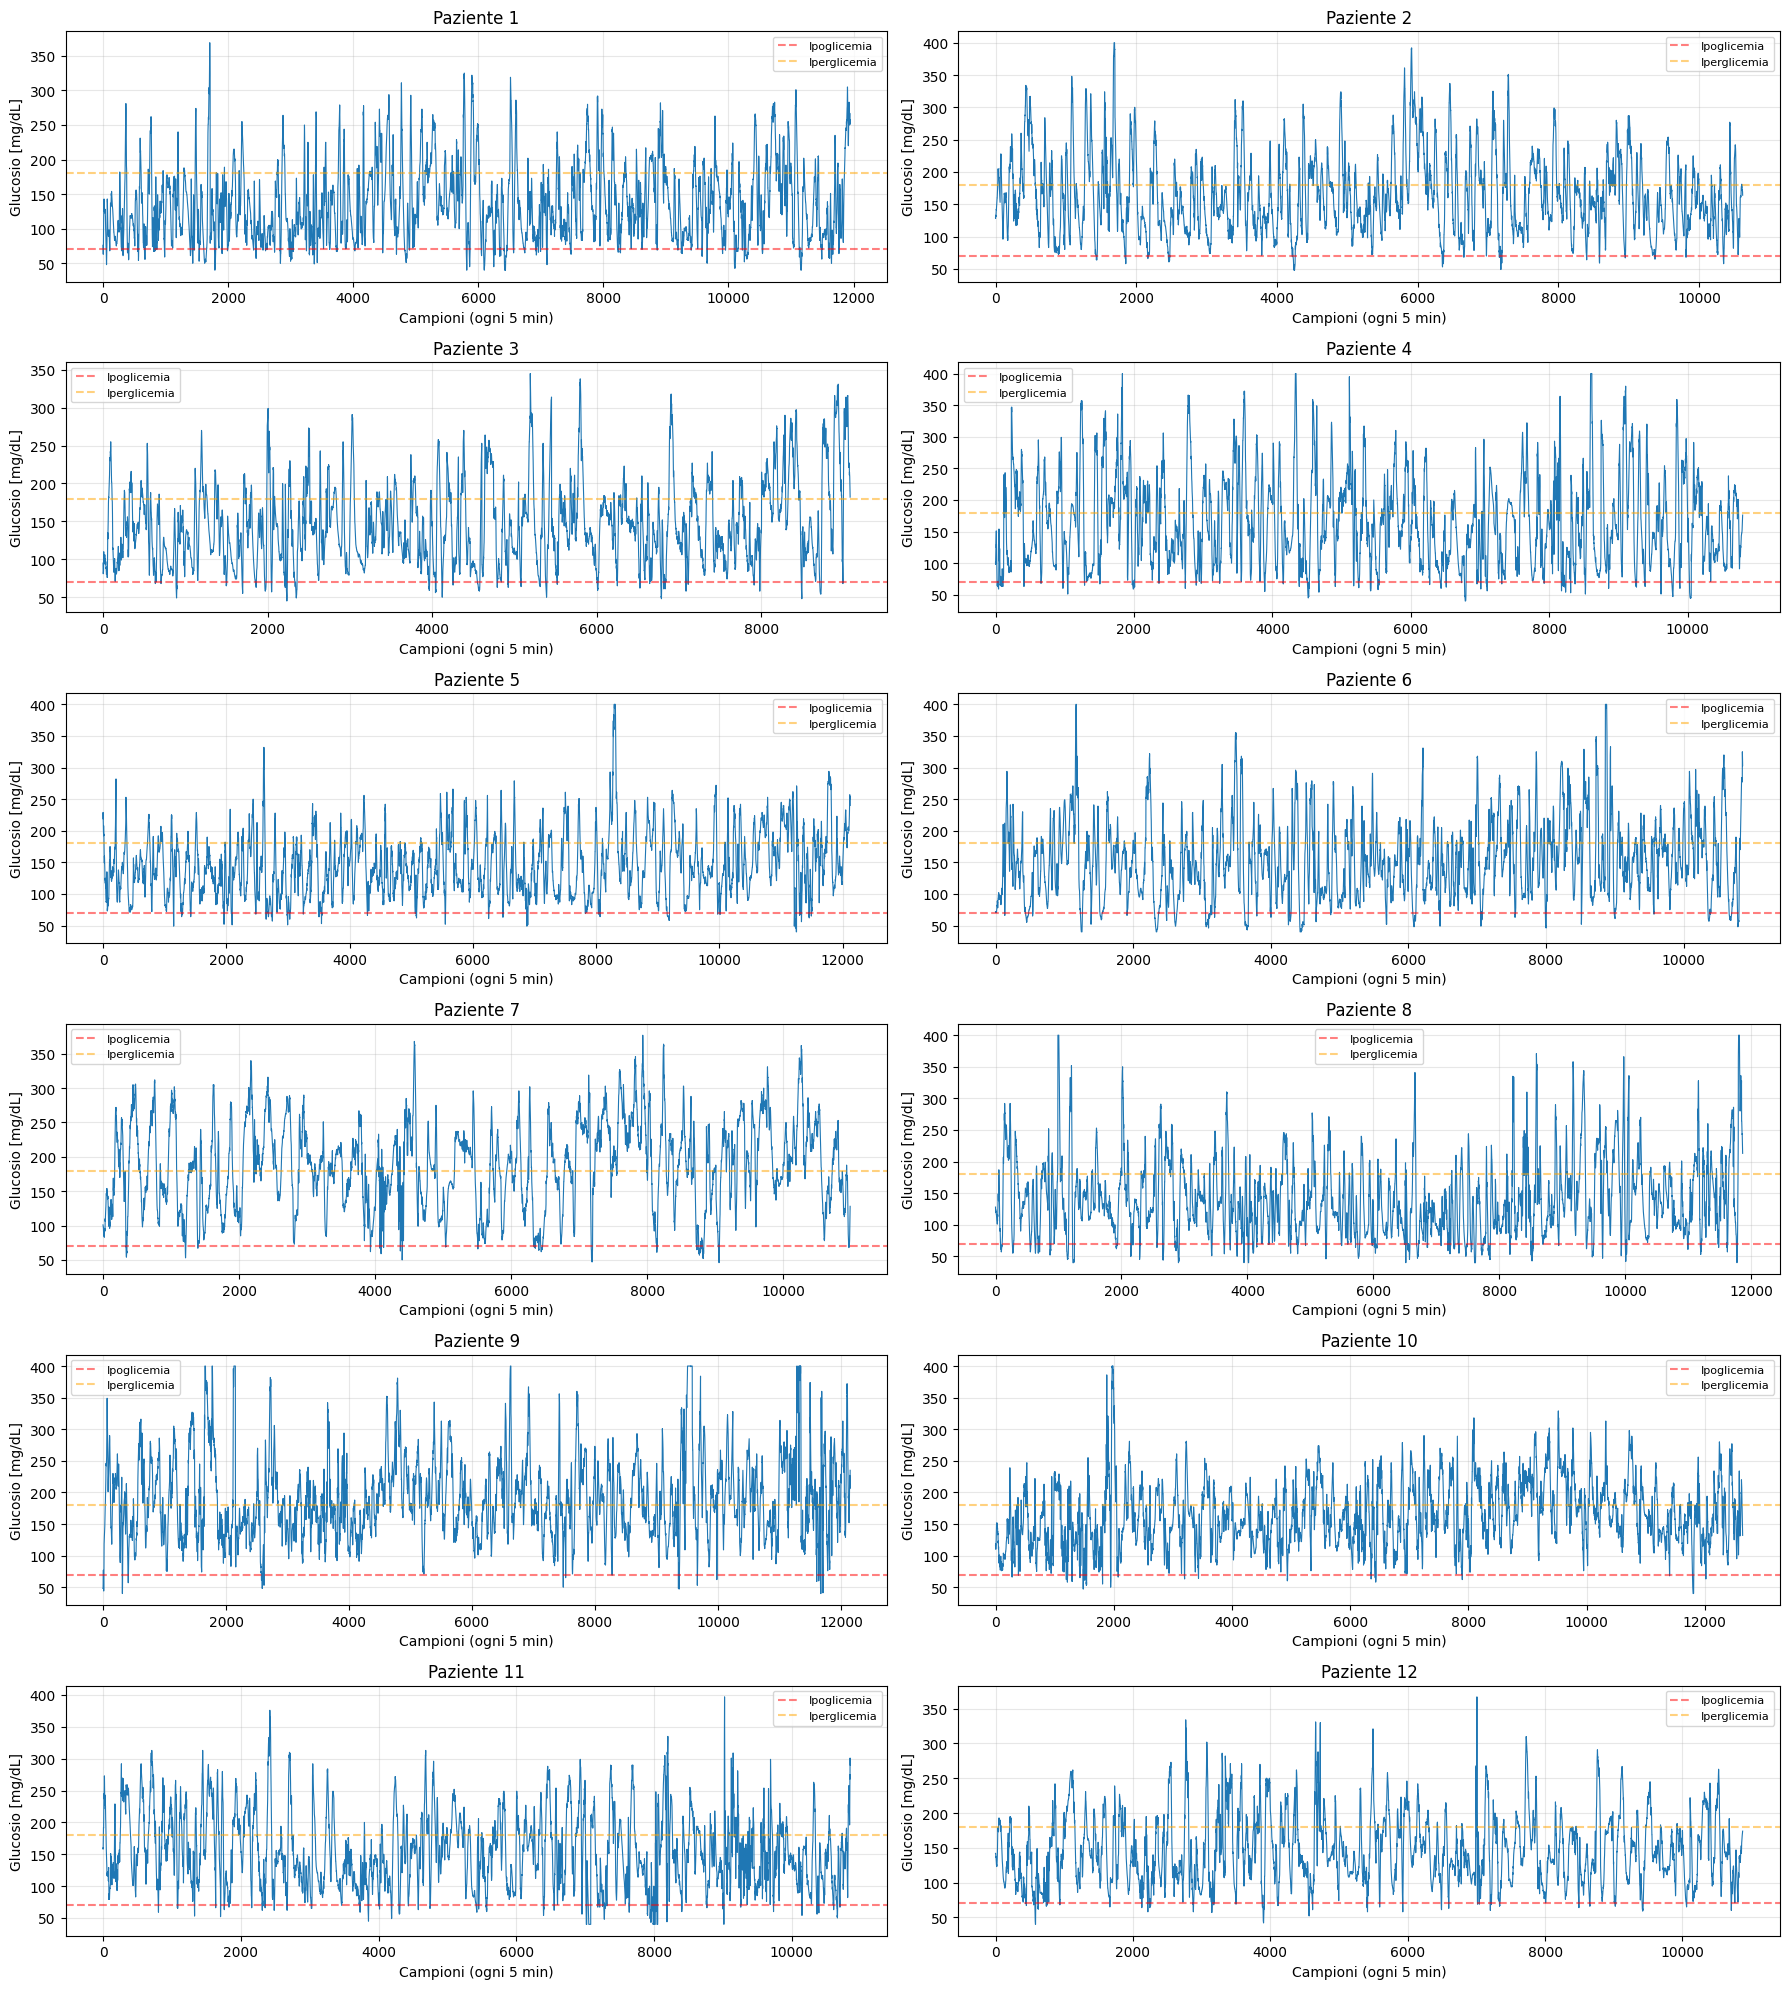

In [5]:
# %% ===== 4. VISUALIZZAZIONE PAZIENTI =====
for i in range(len(cleaned_Train)):
    print(f"Paziente {i+1}: {len(cleaned_Train[i])} campioni")

fig, axes = plt.subplots(6, 2, figsize=(18, 20))
axes = axes.flatten()

for i in range(12):
    signal = cleaned_Train[i]
    axes[i].plot(signal, linewidth=0.8)
    axes[i].set_title(f"Paziente {i+1}")
    axes[i].set_xlabel("Campioni (ogni 5 min)")
    axes[i].set_ylabel("Glucosio [mg/dL]")
    axes[i].axhline(y=70, color='r', linestyle='--', alpha=0.5, label='Ipoglicemia')
    axes[i].axhline(y=180, color='orange', linestyle='--', alpha=0.5, label='Iperglicemia')
    axes[i].grid(True, alpha=0.3)
    axes[i].legend(fontsize=8)

plt.tight_layout()
plt.show()


In [6]:
# %% ===== 5. PARAMETRI =====
WIN_SIZE = 12           # Finestra di input: 12 campioni = 60 minuti (verrà sovrascritta dal tuning)
PREDICTION_HORIZON = 6  # Usato solo per il test della sliding window e il plot
SWSTEP = 1              # Passo della sliding window (overlap massimo)

# PARAMETRI TRAINING
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
N_FOLDS = 12            # leave-one-patient-out su 12 pazienti

# TUNING
PH_FIXED = 6                       # PH di riferimento per il tuning (30 min)
WINDOW_SIZES = [6, 12, 24]         # iperparametro ottimizzato (30, 60, 120 min)
VAL_FRACTION = 0.15                # ultima parte cronologica di ogni paziente di train
PREDICTION_HORIZONS = [6, 12, 18]  # 30, 60, 90 min (analisi, non selezione)

print(f"Window Size iniziale: {WIN_SIZE} campioni ({WIN_SIZE * 5} minuti)")
print(f"Window Size da testare: {WINDOW_SIZES} -> {[w*5 for w in WINDOW_SIZES]} minuti")
print(f"PH di riferimento: {PH_FIXED} campioni ({PH_FIXED * 5} minuti)")
print(f"Prediction Horizons da analizzare: {PREDICTION_HORIZONS} -> {[ph*5 for ph in PREDICTION_HORIZONS]} minuti")
print(f"Epochs: {EPOCHS}, Batch Size: {BATCH_SIZE}, Learning Rate: {LEARNING_RATE}")

Window Size iniziale: 12 campioni (60 minuti)
Window Size da testare: [6, 12, 24] -> [30, 60, 120] minuti
PH di riferimento: 6 campioni (30 minuti)
Prediction Horizons da analizzare: [6, 12, 18] -> [30, 60, 90] minuti
Epochs: 100, Batch Size: 32, Learning Rate: 0.001


In [7]:
# %% ===== 6. SLIDING WINDOW =====
def crea_finestre_con_ph(signal, win_size, prediction_horizon, swstep=1, return_idx=False):
    """Crea finestre input/target scartando quelle che contengono NaN."""
    X, y, idx = [], [], []
    N = len(signal)
    for i in range(0, N - win_size - prediction_horizon + 1, swstep):
        window = signal[i:i + win_size]
        target = signal[i + win_size + prediction_horizon - 1]
        if np.isnan(window).any() or np.isnan(target):
            continue
        X.append(window)
        y.append(target)
        idx.append(i)
    X, y, idx = np.array(X), np.array(y), np.array(idx)
    return (X, y, idx) if return_idx else (X, y)

# Test su un paziente
X_test_func, y_test_func = crea_finestre_con_ph(
    cleaned_Train[0], win_size=WIN_SIZE, prediction_horizon=PREDICTION_HORIZON, swstep=SWSTEP)
print(f"X shape: {X_test_func.shape}, y shape: {y_test_func.shape}")

X shape: (11930, 12), y shape: (11930,)


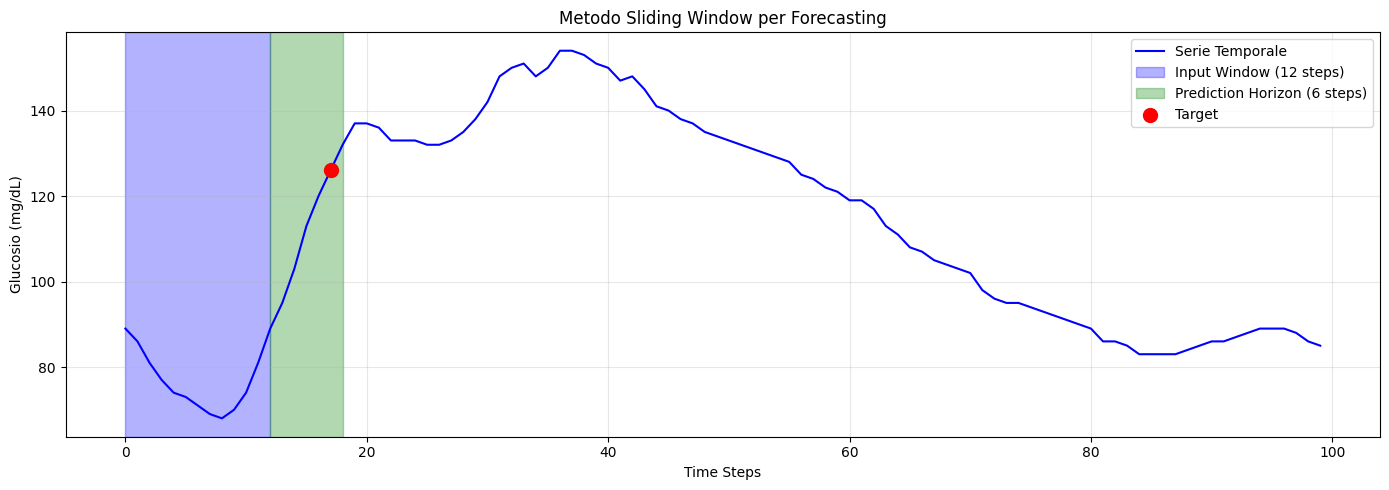

In [8]:
# %% ===== 7. VISUALIZZAZIONE SLIDING WINDOW =====
fig, ax = plt.subplots(figsize=(14, 5))

segment = cleaned_Train[0][100:200]
ax.plot(segment, 'b-', linewidth=1.5, label='Serie Temporale')

ax.axvspan(0, WIN_SIZE, alpha=0.3, color='blue', label=f'Input Window ({WIN_SIZE} steps)')
ax.axvspan(WIN_SIZE, WIN_SIZE + PREDICTION_HORIZON, alpha=0.3, color='green',
           label=f'Prediction Horizon ({PREDICTION_HORIZON} steps)')

target_idx = WIN_SIZE + PREDICTION_HORIZON - 1
ax.scatter([target_idx], [segment[target_idx]], color='red', s=100, zorder=5, label='Target')

ax.set_xlabel('Time Steps')
ax.set_ylabel('Glucosio (mg/dL)')
ax.set_title('Metodo Sliding Window per Forecasting')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# %% ===== 8. NORMALIZZAZIONE =====
def min_max_normalize(X, min_val=None, max_val=None):
    """Normalizza X con Min-Max. Se min/max non sono forniti, li calcola da X."""
    if min_val is None or max_val is None:
        min_val = np.min(X)
        max_val = np.max(X)

    if max_val == min_val:
        X_norm = np.zeros_like(X, dtype=float)
    else:
        X_norm = (X - min_val) / (max_val - min_val)

    return X_norm, min_val, max_val

def denormalize(X_norm, min_val, max_val):
    """Denormalizza X con Min-Max."""
    return X_norm * (max_val - min_val) + min_val

print("Funzioni di normalizzazione definite!")
    

Funzioni di normalizzazione definite!


In [10]:
# %% ===== 9. MODELLO =====
def build_mlp_model(input_shape, learning_rate=0.0005):
    model = Sequential([
        Input(shape=input_shape),

        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),

        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dropout(0.1),

        Dense(16, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    return model

sample_model = build_mlp_model((WIN_SIZE,), learning_rate=LEARNING_RATE)
sample_model.summary()

I0000 00:00:1792670625.085081      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792670625.086748      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,313 (52.00 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [11]:
# %% ===== 10. METRICHE =====
def compute_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def compute_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def compute_mape(y_true, y_pred):
    mask = y_true != 0   # evita divisione per zero
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

print("Funzioni metriche definite!")



Funzioni metriche definite!


In [12]:
# %% ===== 11. LEAVE-ONE-PATIENT-OUT CV =====
def run_cv_for_prediction_horizon(prediction_horizon, cleaned_Train, win_size=12, n_folds=12):
    """Leave-One-Patient-Out CV con MLP. Validation cronologica interna, baseline naive."""
    print(f"\n{'='*70}")
    print(f"PH = {prediction_horizon} ({prediction_horizon*5} min) | WIN = {win_size} ({win_size*5} min)")
    print(f"{'='*70}")

    num_pazienti = len(cleaned_Train)

    # Finestre per paziente, con indice temporale di inizio
    data = []
    for signal in cleaned_Train:
        X, y, idx = crea_finestre_con_ph(signal, win_size, prediction_horizon,
                                         swstep=SWSTEP, return_idx=True)
        data.append((X, y, idx, len(signal)))

    mae_list, rmse_list, mape_list = [], [], []
    val_rmse_list = []
    naive_mae, naive_rmse, naive_mape = [], [], []
    patient_results = []

    for test_id in range(num_pazienti):
        print(f"\n  Fold {test_id+1}/{n_folds} - Test Paziente: {test_id+1}")

        # Split cronologico train/val dentro ogni paziente di train
        X_tr_l, y_tr_l, X_val_l, y_val_l = [], [], [], []
        for i in range(num_pazienti):
            if i == test_id:
                continue
            X, y, idx, L = data[i]
            cut = int(L * (1 - VAL_FRACTION))            # inizio zona validation
            target_idx = idx + win_size + prediction_horizon - 1
            m_tr = target_idx < cut                      # target train PRIMA della validation
            m_val = idx >= cut                           # input validation DOPO il cut
            X_tr_l.append(X[m_tr]);   y_tr_l.append(y[m_tr])
            X_val_l.append(X[m_val]); y_val_l.append(y[m_val])

        X_tr = np.vstack(X_tr_l);   y_tr = np.hstack(y_tr_l)
        X_val = np.vstack(X_val_l); y_val = np.hstack(y_val_l)
        X_test_cv, y_test_cv = data[test_id][0], data[test_id][1]

        # Un solo min/max (X e y sono glucosio), calcolato solo sul train
        X_tr_n, mn, mx = min_max_normalize(X_tr)
        y_tr_n, _, _ = min_max_normalize(y_tr, mn, mx)
        X_val_n, _, _ = min_max_normalize(X_val, mn, mx)
        y_val_n, _, _ = min_max_normalize(y_val, mn, mx)
        X_test_n, _, _ = min_max_normalize(X_test_cv, mn, mx)

        model_hp = build_mlp_model((win_size,), learning_rate=LEARNING_RATE)

        early_stop = EarlyStopping(monitor='val_loss', patience=10,
                                   restore_best_weights=True, verbose=0)
        lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                         patience=5, min_lr=1e-6, verbose=0)

        model_hp.fit(X_tr_n, y_tr_n,
                     validation_data=(X_val_n, y_val_n),
                     epochs=EPOCHS, batch_size=BATCH_SIZE,
                     callbacks=[early_stop, lr_scheduler], verbose=0)

        # Predizione test e denormalizzazione
        y_pred_denorm_cv = denormalize(model_hp.predict(X_test_n, verbose=0).flatten(), mn, mx)
        y_test_denorm_cv = y_test_cv                      # già in mg/dL

        # Metrica su validation (serve a scegliere l'iperparametro)
        y_val_pred = denormalize(model_hp.predict(X_val_n, verbose=0).flatten(), mn, mx)
        val_rmse_list.append(compute_rmse(y_val, y_val_pred))

        mae_cv = compute_mae(y_test_denorm_cv, y_pred_denorm_cv)
        rmse_cv = compute_rmse(y_test_denorm_cv, y_pred_denorm_cv)
        mape_cv = compute_mape(y_test_denorm_cv, y_pred_denorm_cv)
        mae_list.append(mae_cv); rmse_list.append(rmse_cv); mape_list.append(mape_cv)

        # Baseline naive (ultimo valore osservato nella finestra)
        y_naive = X_test_cv[:, -1]
        naive_mae.append(compute_mae(y_test_denorm_cv, y_naive))
        naive_rmse.append(compute_rmse(y_test_denorm_cv, y_naive))
        naive_mape.append(compute_mape(y_test_denorm_cv, y_naive))

        patient_results.append({
            'patient_id': test_id + 1,
            'mae': mae_cv, 'rmse': rmse_cv, 'mape': mape_cv,
            'y_true': y_test_denorm_cv, 'y_pred': y_pred_denorm_cv
        })

        print(f"    MAE: {mae_cv:.2f}, RMSE: {rmse_cv:.2f}, MAPE: {mape_cv:.2f}% "
              f"| naive RMSE: {naive_rmse[-1]:.2f}")

        del model_hp
        tf.keras.backend.clear_session()

    results = {
        'prediction_horizon': prediction_horizon,
        'ph_minutes': prediction_horizon * 5,
        'win_size': win_size,
        'mae_mean': np.mean(mae_list),   'mae_std': np.std(mae_list),
        'rmse_mean': np.mean(rmse_list), 'rmse_std': np.std(rmse_list),
        'mape_mean': np.mean(mape_list), 'mape_std': np.std(mape_list),
        'val_rmse_mean': np.mean(val_rmse_list),
        'naive_mae_mean': np.mean(naive_mae),
        'naive_rmse_mean': np.mean(naive_rmse),
        'naive_mape_mean': np.mean(naive_mape),
    }

    print(f"\n  >>> RISULTATI PH={prediction_horizon*5}min, WIN={win_size*5}min:")
    print(f"      MAE:  {results['mae_mean']:.2f} ± {results['mae_std']:.2f} mg/dL  (naive {results['naive_mae_mean']:.2f})")
    print(f"      RMSE: {results['rmse_mean']:.2f} ± {results['rmse_std']:.2f} mg/dL  (naive {results['naive_rmse_mean']:.2f})")
    print(f"      MAPE: {results['mape_mean']:.2f} ± {results['mape_std']:.2f} %  (naive {results['naive_mape_mean']:.2f})")
    print(f"      Val RMSE (per il tuning): {results['val_rmse_mean']:.2f}")

    return results, patient_results


In [13]:
# %% ===== 12. ESECUZIONE: TUNING + ANALISI PH =====
# STEP 1: tuning di WIN_SIZE con PH fisso, scelta sul VALIDATION
tuning_runs = {}
for w in WINDOW_SIZES:
    tuning_runs[w] = run_cv_for_prediction_horizon(
        PH_FIXED, cleaned_Train, win_size=w, n_folds=N_FOLDS)

print("\n" + "="*70)
print(f"TUNING WIN_SIZE (PH = {PH_FIXED*5} min)")
print(f"{'WIN (min)':<10} | {'Val RMSE':<10} | {'Test RMSE (mean ± std)':<24}")
for w, (r, _) in tuning_runs.items():
    print(f"{w*5:<10} | {r['val_rmse_mean']:<10.2f} | {r['rmse_mean']:.2f} ± {r['rmse_std']:.2f}")

best_win = min(tuning_runs, key=lambda w: tuning_runs[w][0]['val_rmse_mean'])
WIN_SIZE = best_win
print(f"\nMiglior WIN_SIZE (su validation): {best_win} campioni ({best_win*5} min)")

# STEP 2: performance a diversi PH con il WIN_SIZE scelto
all_hp_results = []
all_patient_results = {}
for ph in PREDICTION_HORIZONS:
    if ph == PH_FIXED:
        results, patient_results = tuning_runs[best_win]     # riuso, niente ri-training
    else:
        results, patient_results = run_cv_for_prediction_horizon(
            ph, cleaned_Train, win_size=best_win, n_folds=N_FOLDS)
    all_hp_results.append(results)
    all_patient_results[ph] = patient_results




PH = 6 (30 min) | WIN = 6 (30 min)

  Fold 1/12 - Test Paziente: 1


I0000 00:00:1792670632.594943     126 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


    MAE: 17.31, RMSE: 23.24, MAPE: 15.02% | naive RMSE: 27.55

  Fold 2/12 - Test Paziente: 2
    MAE: 15.14, RMSE: 20.58, MAPE: 9.99% | naive RMSE: 24.38

  Fold 3/12 - Test Paziente: 3
    MAE: 16.37, RMSE: 22.07, MAPE: 12.91% | naive RMSE: 25.49

  Fold 4/12 - Test Paziente: 4
    MAE: 19.18, RMSE: 27.97, MAPE: 13.07% | naive RMSE: 32.59

  Fold 5/12 - Test Paziente: 5
    MAE: 12.81, RMSE: 18.12, MAPE: 9.44% | naive RMSE: 21.14

  Fold 6/12 - Test Paziente: 6
    MAE: 18.23, RMSE: 26.08, MAPE: 14.16% | naive RMSE: 30.17

  Fold 7/12 - Test Paziente: 7
    MAE: 14.90, RMSE: 20.67, MAPE: 8.72% | naive RMSE: 20.66

  Fold 8/12 - Test Paziente: 8
    MAE: 17.60, RMSE: 24.97, MAPE: 15.33% | naive RMSE: 28.83

  Fold 9/12 - Test Paziente: 9
    MAE: 20.04, RMSE: 29.49, MAPE: 11.19% | naive RMSE: 31.64

  Fold 10/12 - Test Paziente: 10
    MAE: 16.22, RMSE: 22.79, MAPE: 11.13% | naive RMSE: 24.92

  Fold 11/12 - Test Paziente: 11
    MAE: 17.99, RMSE: 26.28, MAPE: 13.63% | naive RMSE: 30.

In [14]:
# %% ===== 13. RISULTATI: TABELLE =====
print("\n" + "="*80)
print("TABELLA RISULTATI: METRICHE PER PAZIENTE E PREDICTION HORIZON")
print("="*80)

all_data = []
for ph in PREDICTION_HORIZONS:
    for patient_result in all_patient_results[ph]:
        all_data.append({
            'PH (campioni)': ph,
            'PH (minuti)': ph * 5,
            'Paziente': patient_result['patient_id'],
            'MAE (mg/dL)': patient_result['mae'],
            'RMSE (mg/dL)': patient_result['rmse'],
            'MAPE (%)': patient_result['mape']
        })

df_results = pd.DataFrame(all_data)

for ph in PREDICTION_HORIZONS:
    print(f"\n{'='*60}")
    print(f"PREDICTION HORIZON = {ph} campioni ({ph*5} minuti)")
    print(f"{'='*60}")

    df_ph = df_results[df_results['PH (campioni)'] == ph]

    print(f"\n{'Paziente':<10} | {'MAE (mg/dL)':<14} | {'RMSE (mg/dL)':<14} | {'MAPE (%)':<12}")
    print("-"*60)

    for _, row in df_ph.iterrows():
        print(f"{int(row['Paziente']):<10} | {row['MAE (mg/dL)']:<14.2f} | {row['RMSE (mg/dL)']:<14.2f} | {row['MAPE (%)']:<12.2f}")

    print("-"*60)

print("\n" + "="*80)
print("TABELLA RIASSUNTIVA: MEDIE (sui 12 pazienti) PER PREDICTION HORIZON")
print("="*80)

print(f"\n{'PH (min)':<12} | {'MAE (mg/dL)':<20} | {'RMSE (mg/dL)':<20} | {'MAPE (%)':<18}")
print("-"*80)

for r in all_hp_results:
    print(f"{r['ph_minutes']:<12} | "
          f"{r['mae_mean']:.2f} ± {r['mae_std']:.2f}        | "
          f"{r['rmse_mean']:.2f} ± {r['rmse_std']:.2f}        | "
          f"{r['mape_mean']:.2f} ± {r['mape_std']:.2f}")

print("-"*80)

# PH di riferimento (NON scelto per RMSE minimo)
best_ph = PH_FIXED
best_result = next(r for r in all_hp_results if r['prediction_horizon'] == best_ph)

print(f"\n{'='*80}")
print(f"PH DI RIFERIMENTO: {best_ph} campioni ({best_ph * 5} minuti)")
print(f"{'='*80}")
print(f"  MAE:  {best_result['mae_mean']:.2f} ± {best_result['mae_std']:.2f} mg/dL")
print(f"  RMSE: {best_result['rmse_mean']:.2f} ± {best_result['rmse_std']:.2f} mg/dL")
print(f"  MAPE: {best_result['mape_mean']:.2f} ± {best_result['mape_std']:.2f} %")

print(f"\nBaseline naive (ultimo valore) a PH={best_ph*5} min: "
      f"MAE {best_result['naive_mae_mean']:.2f}, "
      f"RMSE {best_result['naive_rmse_mean']:.2f}, "
      f"MAPE {best_result['naive_mape_mean']:.2f}%")



TABELLA RISULTATI: METRICHE PER PAZIENTE E PREDICTION HORIZON

PREDICTION HORIZON = 6 campioni (30 minuti)

Paziente   | MAE (mg/dL)    | RMSE (mg/dL)   | MAPE (%)    
------------------------------------------------------------
1          | 18.69          | 24.35          | 17.23       
2          | 15.13          | 20.83          | 9.86        
3          | 16.31          | 22.15          | 12.58       
4          | 19.56          | 28.39          | 13.29       
5          | 12.70          | 17.76          | 9.82        
6          | 17.76          | 25.81          | 13.39       
7          | 15.04          | 20.82          | 9.06        
8          | 17.02          | 24.47          | 14.60       
9          | 21.18          | 30.99          | 11.39       
10         | 16.19          | 22.89          | 10.84       
11         | 18.41          | 26.71          | 14.31       
12         | 13.40          | 19.96          | 10.09       
--------------------------------------------------

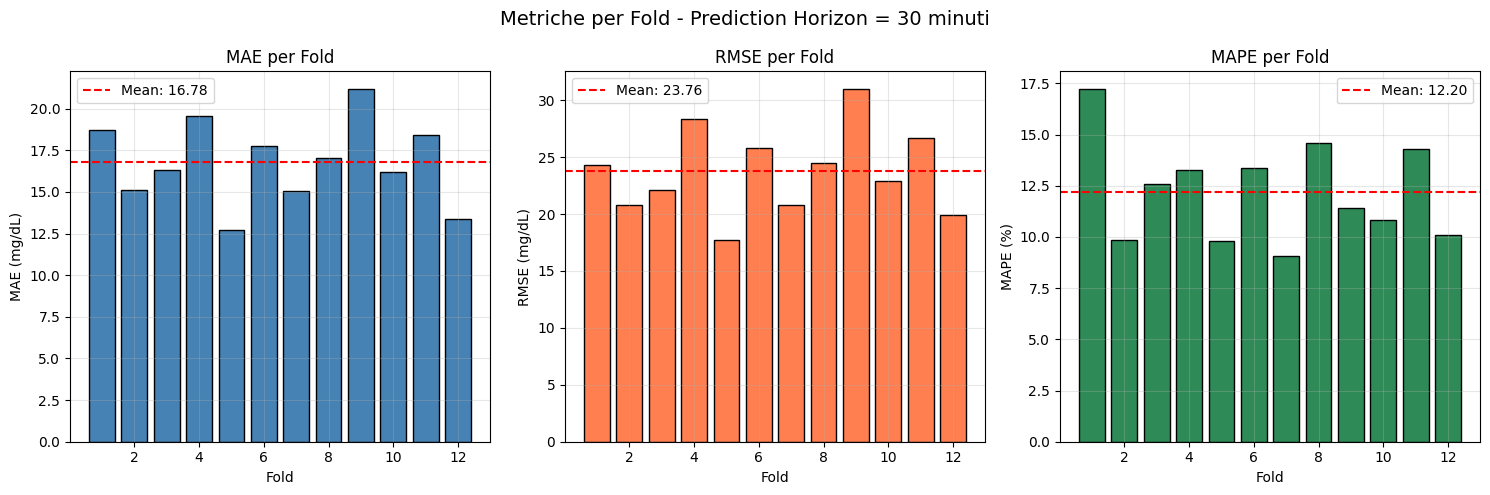

In [15]:
# %% ===== 14. GRAFICO METRICHE PER FOLD (PH di riferimento) =====
best_ph = PH_FIXED
patient_data = all_patient_results[best_ph]

all_mae_denorm = [p['mae'] for p in patient_data]
all_rmse_denorm = [p['rmse'] for p in patient_data]
all_mape = [p['mape'] for p in patient_data]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
folds = range(1, N_FOLDS + 1)

axes[0].bar(folds, all_mae_denorm, color='steelblue', edgecolor='black')
axes[0].axhline(y=np.mean(all_mae_denorm), color='red', linestyle='--', label=f'Mean: {np.mean(all_mae_denorm):.2f}')
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('MAE (mg/dL)')
axes[0].set_title('MAE per Fold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].bar(folds, all_rmse_denorm, color='coral', edgecolor='black')
axes[1].axhline(y=np.mean(all_rmse_denorm), color='red', linestyle='--', label=f'Mean: {np.mean(all_rmse_denorm):.2f}')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('RMSE (mg/dL)')
axes[1].set_title('RMSE per Fold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].bar(folds, all_mape, color='seagreen', edgecolor='black')
axes[2].axhline(y=np.mean(all_mape), color='red', linestyle='--', label=f'Mean: {np.mean(all_mape):.2f}')
axes[2].set_xlabel('Fold')
axes[2].set_ylabel('MAPE (%)')
axes[2].set_title('MAPE per Fold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Metriche per Fold - Prediction Horizon = {best_ph*5} minuti', fontsize=14)
plt.tight_layout()
plt.show()

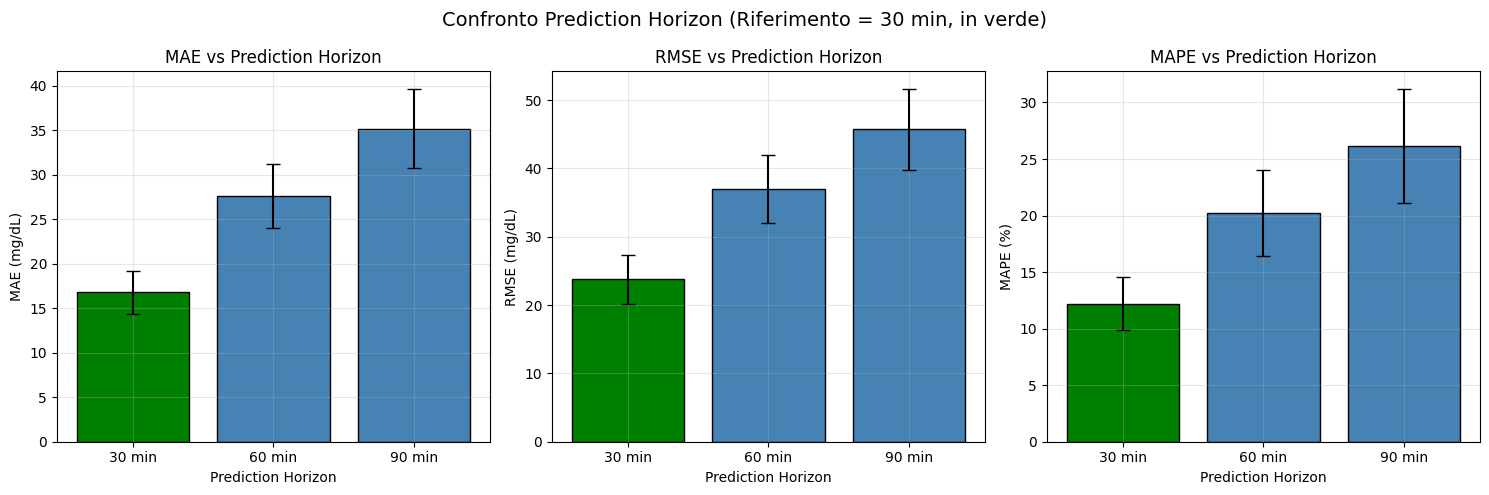

In [16]:
# %% ===== 15. CONFRONTO PER PREDICTION HORIZON =====
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

ph_labels = [f"{r['ph_minutes']} min" for r in all_hp_results]
best_ph = PH_FIXED
colors = ['green' if r['prediction_horizon'] == best_ph else 'steelblue' for r in all_hp_results]

mae_means = [r['mae_mean'] for r in all_hp_results]
mae_stds = [r['mae_std'] for r in all_hp_results]
axes[0].bar(ph_labels, mae_means, yerr=mae_stds, capsize=5, color=colors, edgecolor='black')
axes[0].set_xlabel('Prediction Horizon')
axes[0].set_ylabel('MAE (mg/dL)')
axes[0].set_title('MAE vs Prediction Horizon')
axes[0].grid(True, alpha=0.3)

rmse_means = [r['rmse_mean'] for r in all_hp_results]
rmse_stds = [r['rmse_std'] for r in all_hp_results]
axes[1].bar(ph_labels, rmse_means, yerr=rmse_stds, capsize=5, color=colors, edgecolor='black')
axes[1].set_xlabel('Prediction Horizon')
axes[1].set_ylabel('RMSE (mg/dL)')
axes[1].set_title('RMSE vs Prediction Horizon')
axes[1].grid(True, alpha=0.3)

mape_means = [r['mape_mean'] for r in all_hp_results]
mape_stds = [r['mape_std'] for r in all_hp_results]
axes[2].bar(ph_labels, mape_means, yerr=mape_stds, capsize=5, color=colors, edgecolor='black')
axes[2].set_xlabel('Prediction Horizon')
axes[2].set_ylabel('MAPE (%)')
axes[2].set_title('MAPE vs Prediction Horizon')
axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Confronto Prediction Horizon (Riferimento = {best_ph*5} min, in verde)', fontsize=14)
plt.tight_layout()
plt.show()


GRAFICI INDIVIDUALI DETTAGLIATI


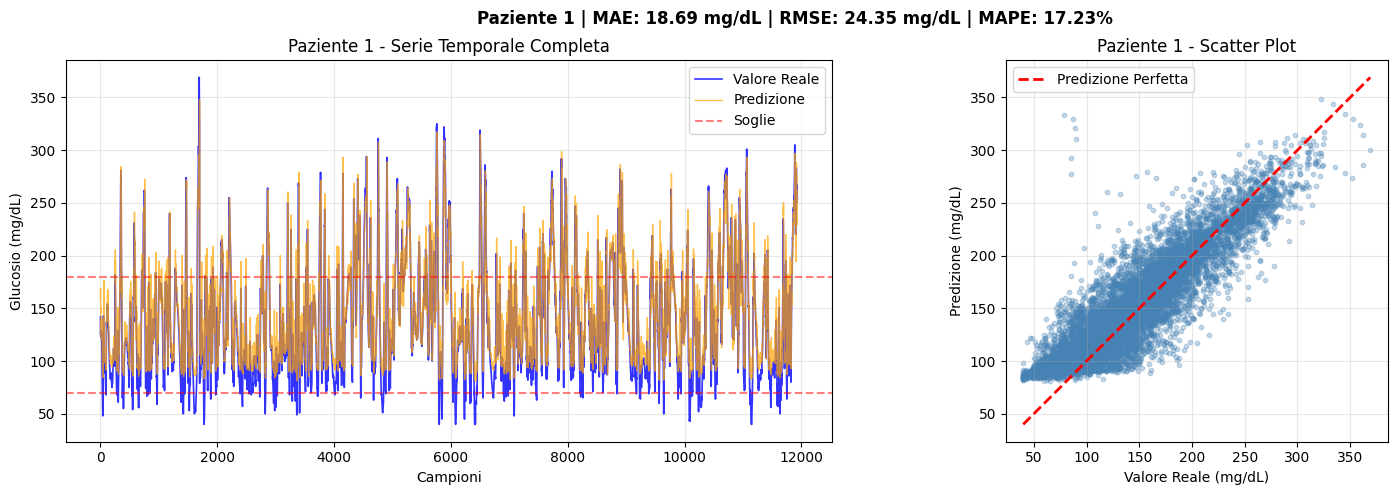

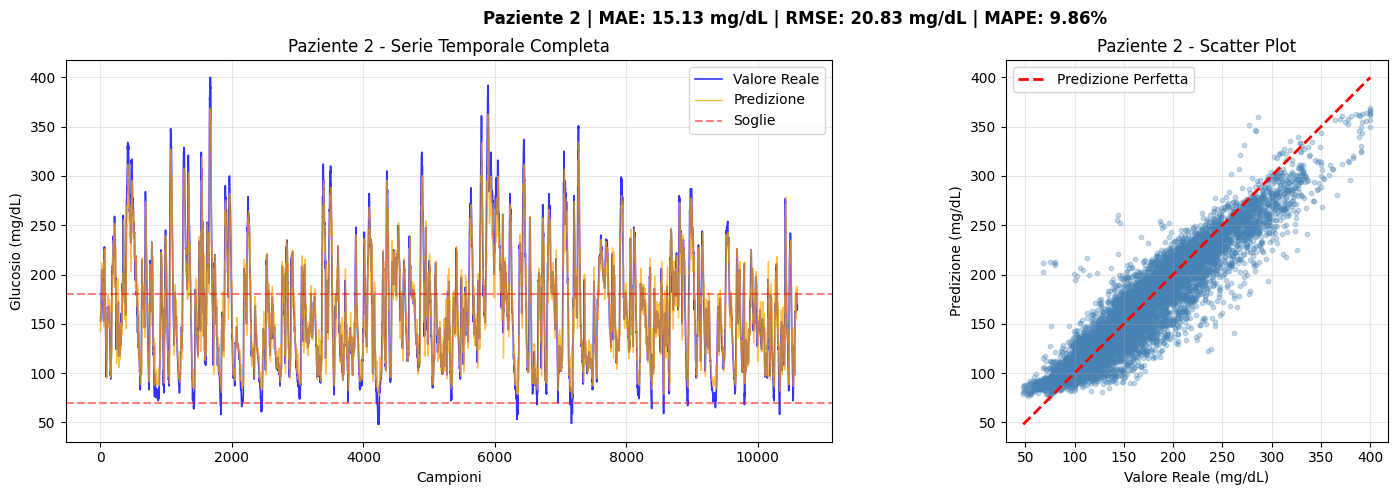

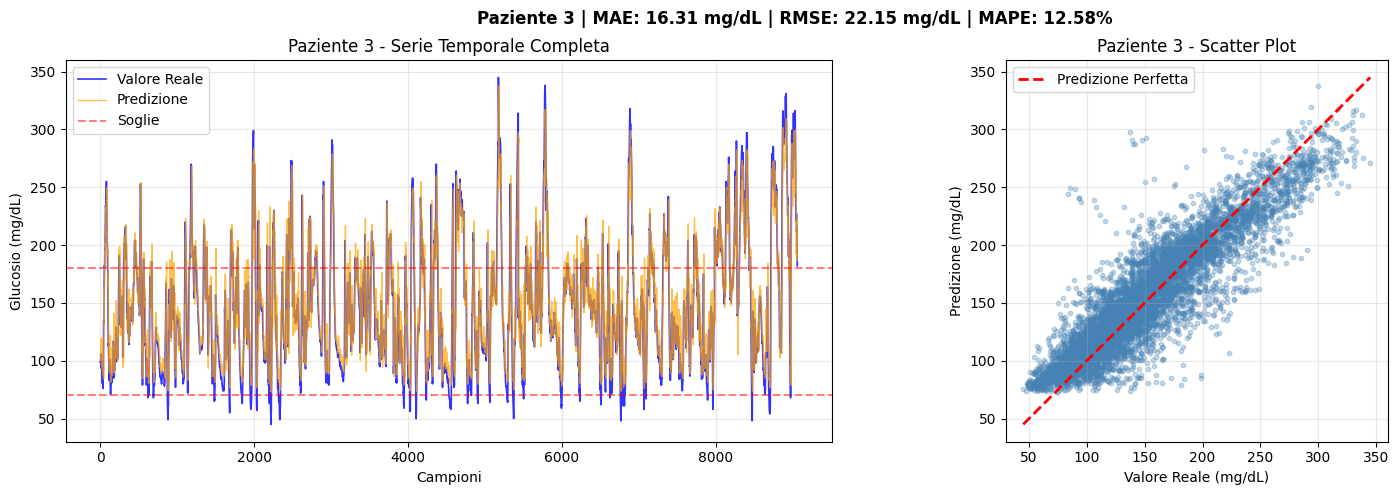

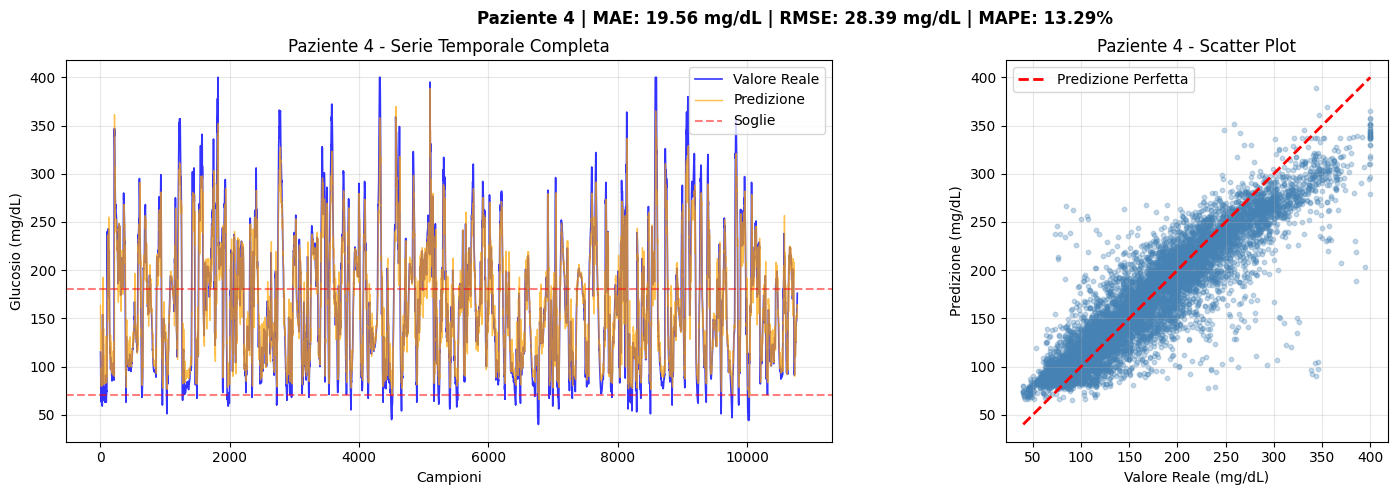

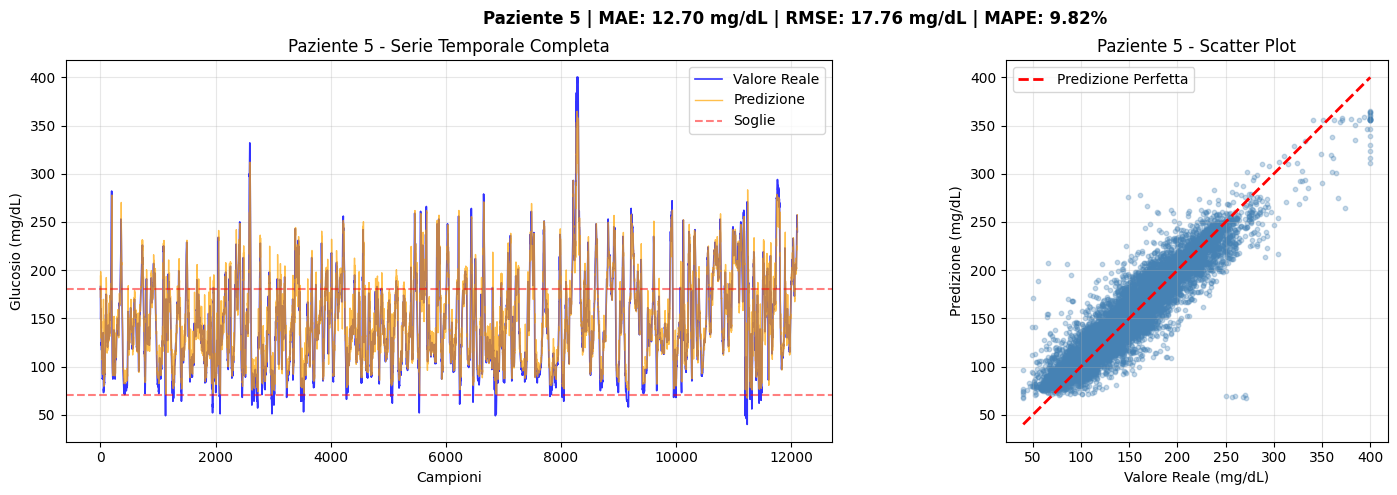

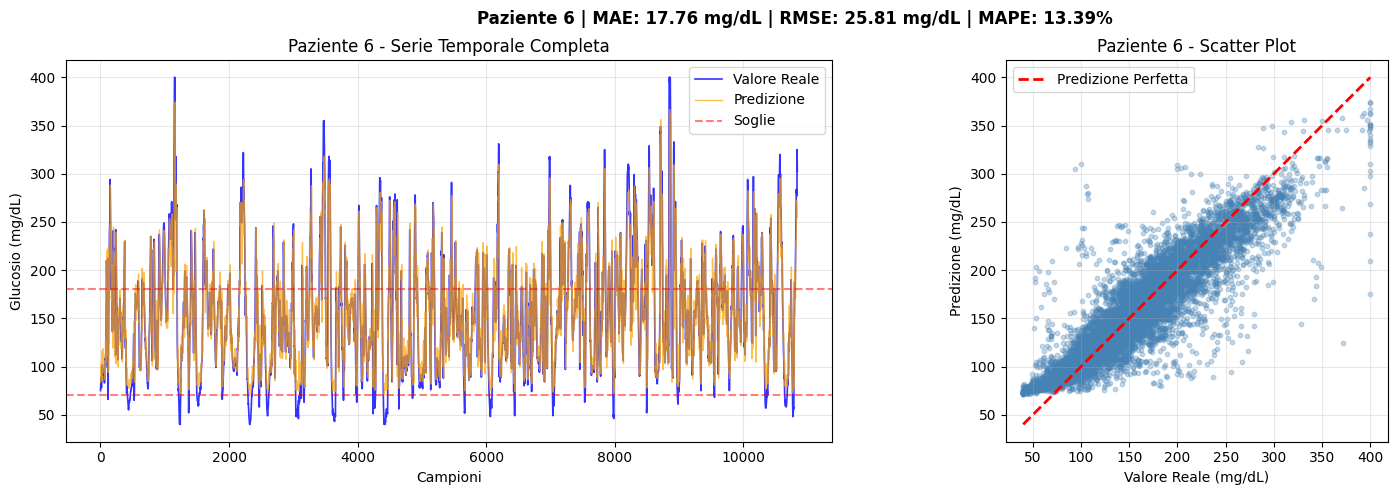

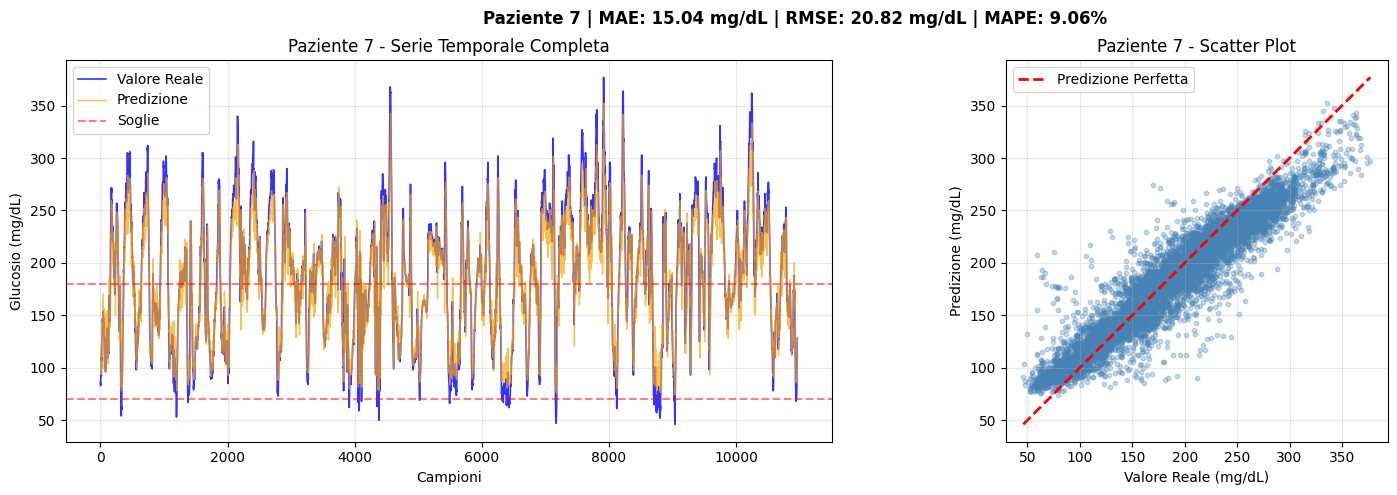

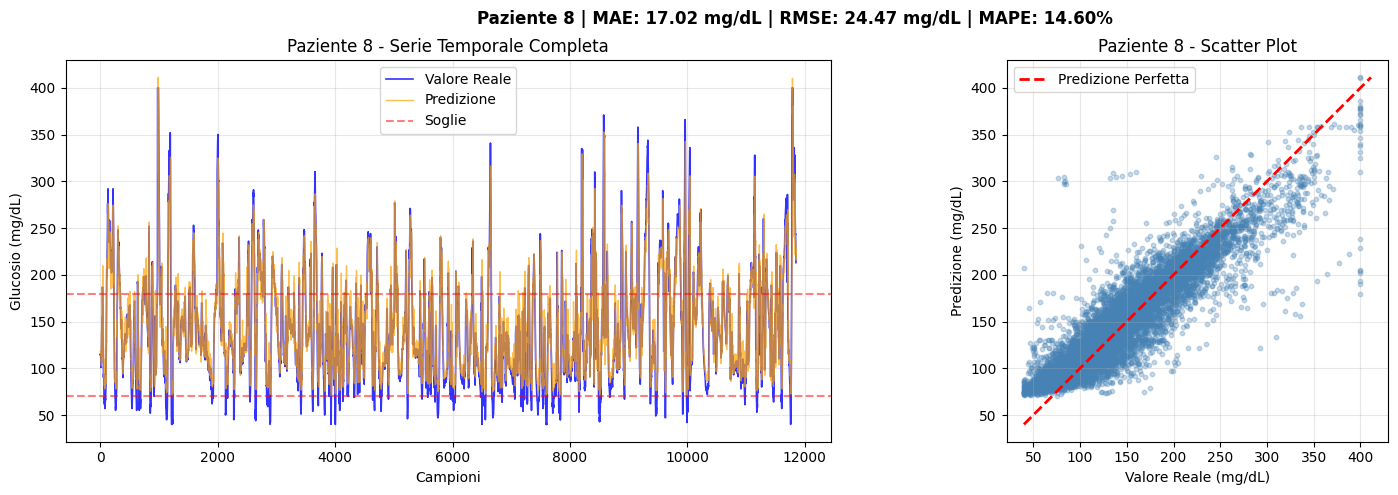

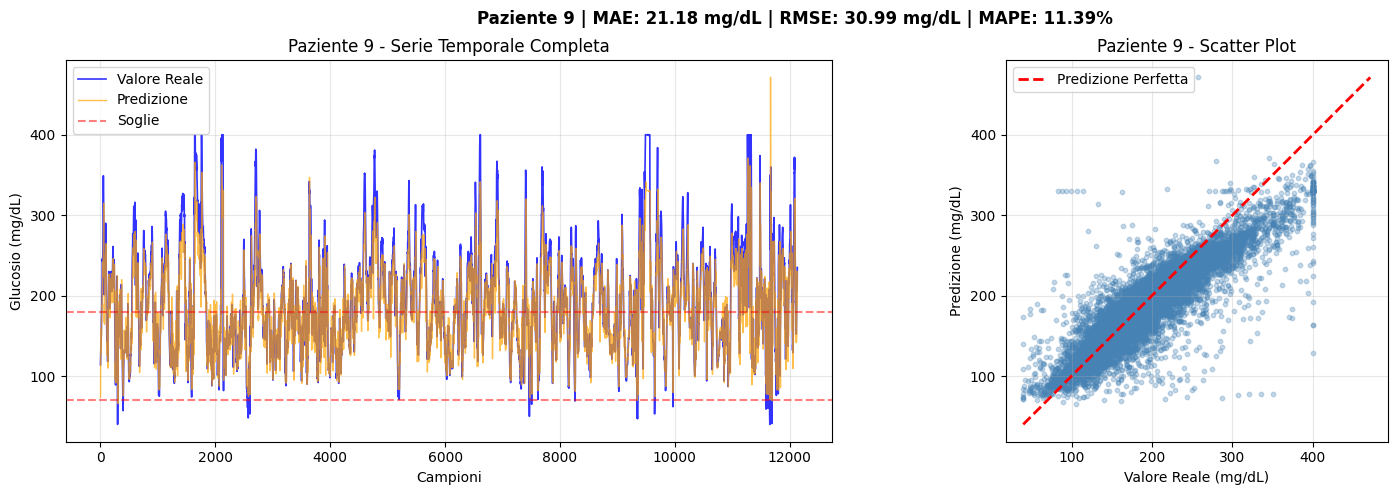

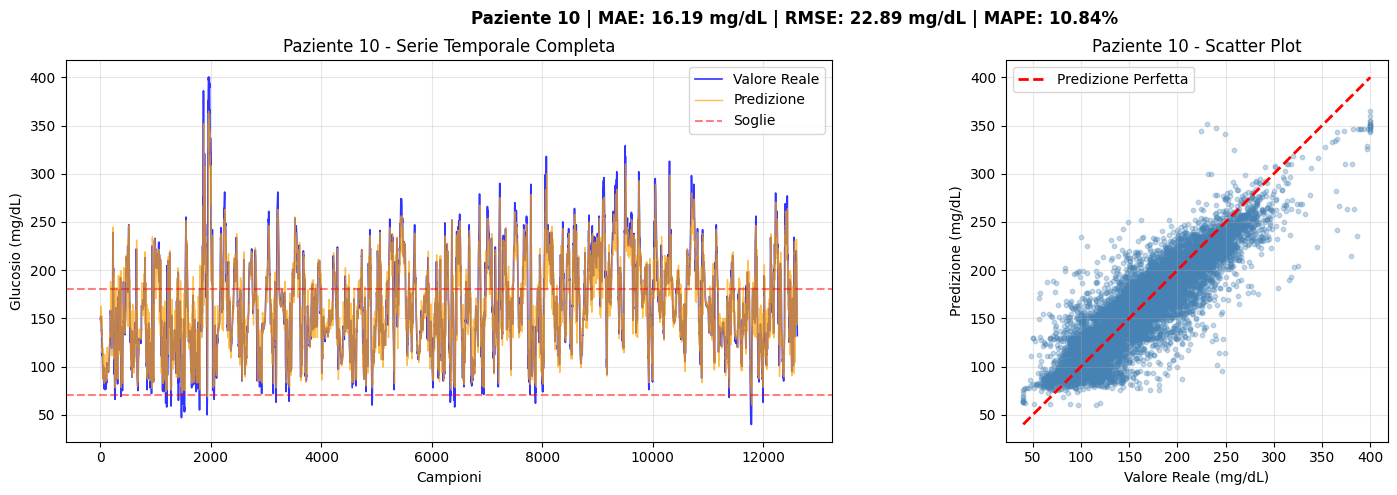

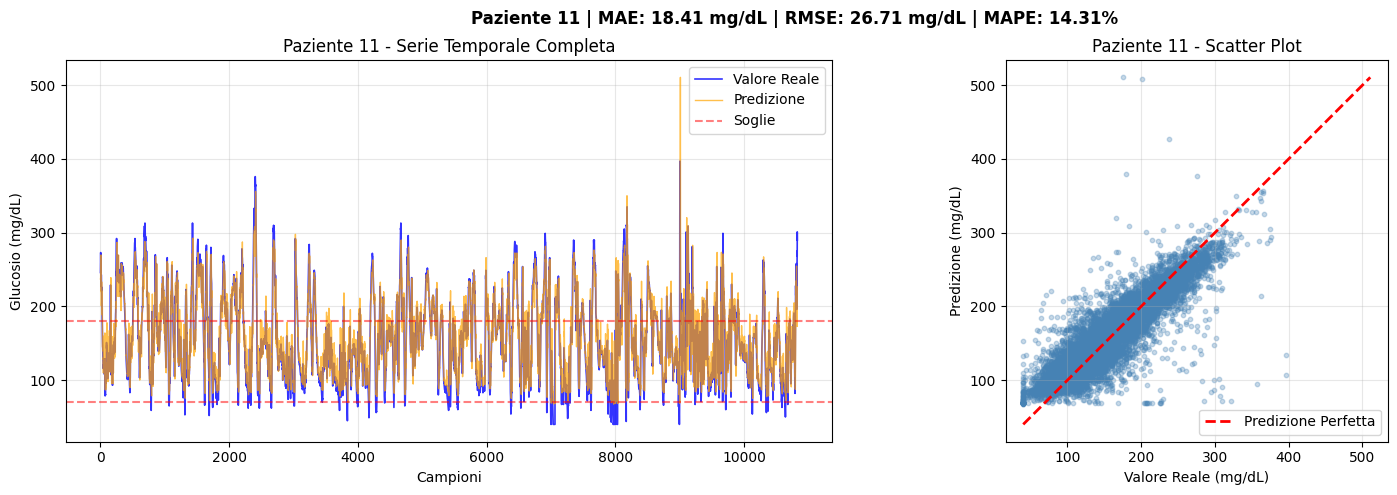

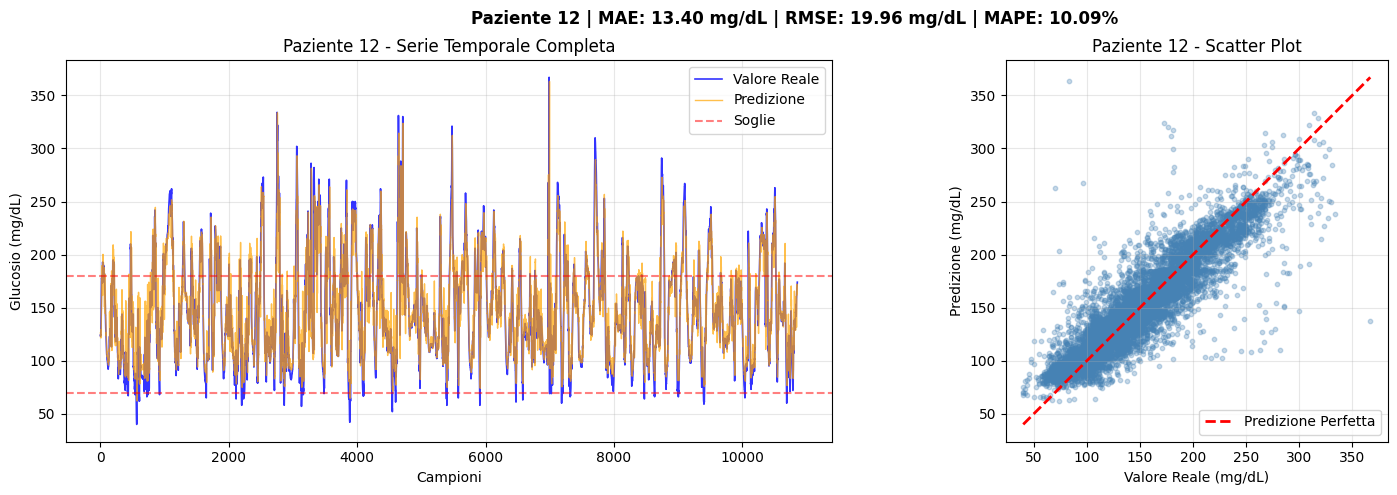

In [17]:
# %% ===== 16. GRAFICI INDIVIDUALI PER PAZIENTE (PH di riferimento) =====
print("\n" + "="*70)
print("GRAFICI INDIVIDUALI DETTAGLIATI")
print("="*70)

for patient_result in all_patient_results[PH_FIXED]:
    y_true = patient_result['y_true']
    y_pred = patient_result['y_pred']
    patient_id = patient_result['patient_id']

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    ax1 = axes[0]
    ax1.plot(y_true, label='Valore Reale', linewidth=1.2, color='blue', alpha=0.8)
    ax1.plot(y_pred, label='Predizione', linewidth=1, color='orange', alpha=0.7)
    ax1.axhline(y=70, color='red', linestyle='--', alpha=0.5, label='Soglie')
    ax1.axhline(y=180, color='red', linestyle='--', alpha=0.5)
    ax1.set_xlabel('Campioni')
    ax1.set_ylabel('Glucosio (mg/dL)')
    ax1.set_title(f'Paziente {patient_id} - Serie Temporale Completa')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2 = axes[1]
    ax2.scatter(y_true, y_pred, alpha=0.3, s=10, color='steelblue')
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax2.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Predizione Perfetta')
    ax2.set_xlabel('Valore Reale (mg/dL)')
    ax2.set_ylabel('Predizione (mg/dL)')
    ax2.set_title(f'Paziente {patient_id} - Scatter Plot')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_aspect('equal', adjustable='box')

    plt.suptitle(f'Paziente {patient_id} | MAE: {patient_result["mae"]:.2f} mg/dL | '
                 f'RMSE: {patient_result["rmse"]:.2f} mg/dL | MAPE: {patient_result["mape"]:.2f}%',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.show()



TABELLA RIASSUNTIVA HYPERPARAMETER TUNING - WINDOW SIZE

| PH (min)   | MAE (mg/dL)        | RMSE (mg/dL)       | MAPE (%)           |
|------------|--------------------|--------------------|--------------------|
| 30 *RIF.*  | 16.78 ± 2.40        | 23.76 ± 3.63        | 12.20 ± 2.35        |
| 60         | 27.60 ± 3.56        | 36.99 ± 5.02        | 20.21 ± 3.80        |
| 90         | 35.18 ± 4.44        | 45.75 ± 5.90        | 26.16 ± 5.04        |
|------------|--------------------|--------------------|--------------------|

Iperparametro ottimizzato: WINDOW SIZE
Valori testati: [30, 60, 120] minuti
Miglior valore: WIN = 60 minuti

RISULTATI PER PAZIENTE - PREDICTION HORIZON = 30 minuti

| Paziente   | MAE (mg/dL)    | RMSE (mg/dL)   | MAPE (%)       |
|------------|----------------|----------------|----------------|
| 1          | 18.69          | 24.35          | 17.23          |
| 2          | 15.13          | 20.83          | 9.86           |
| 3          | 16.31          | 22

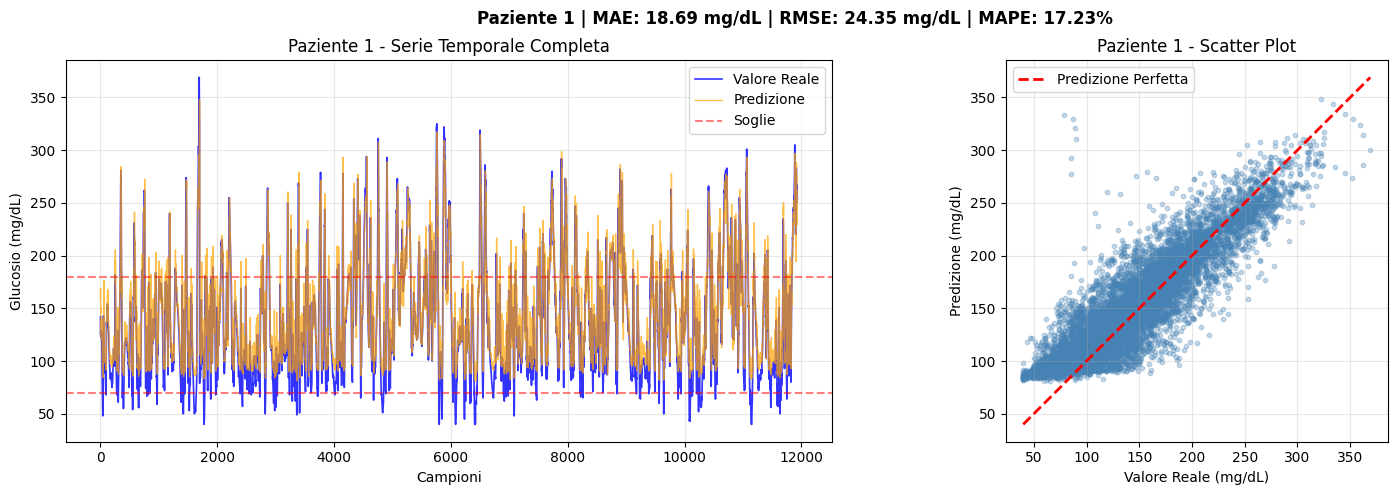

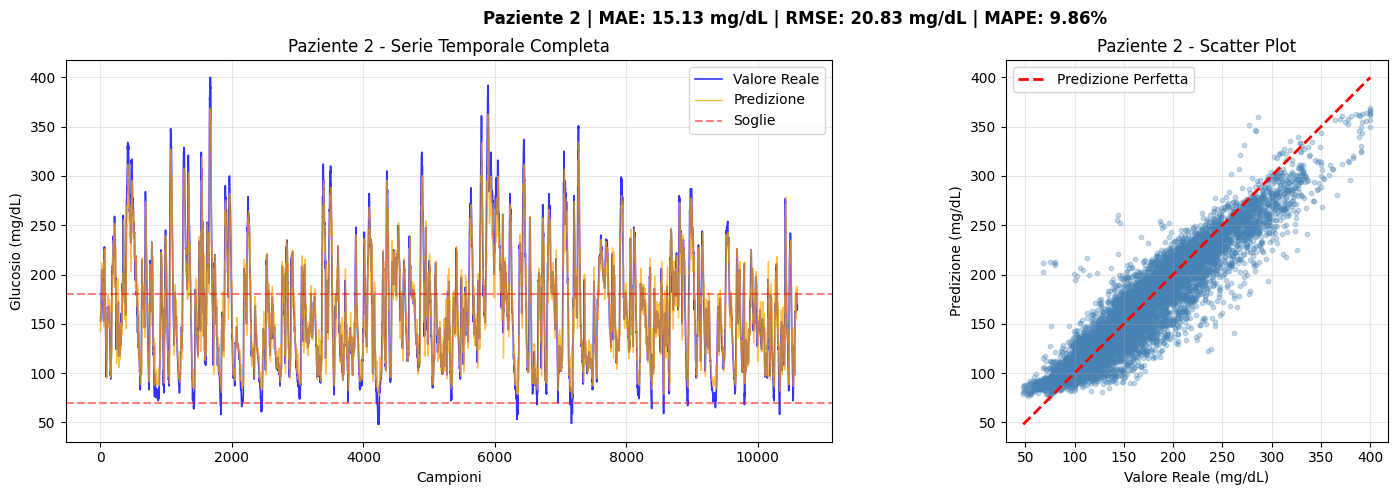

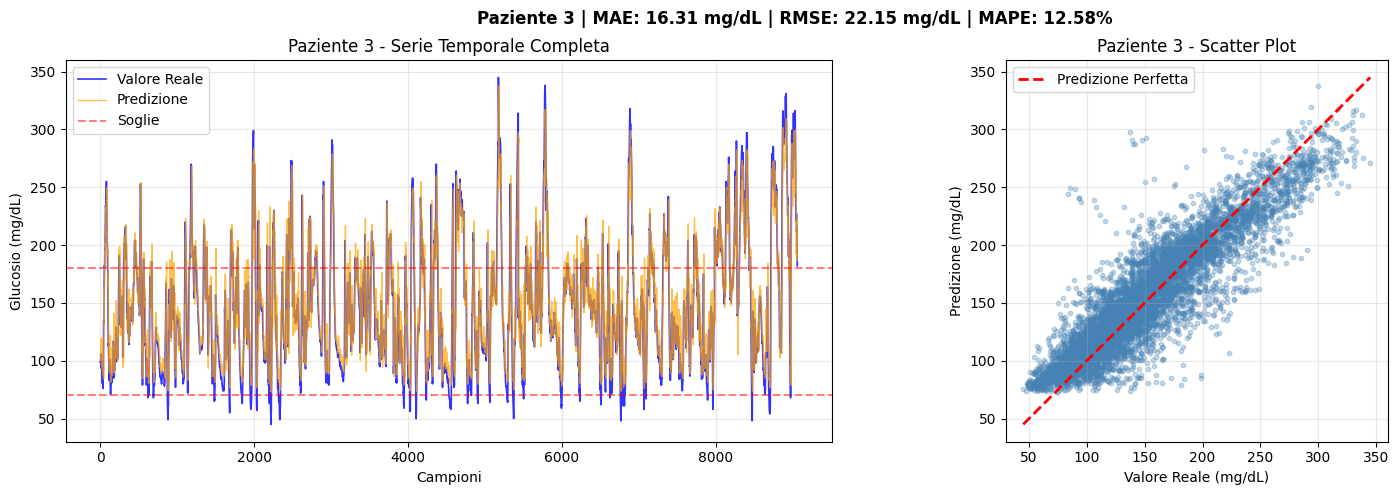

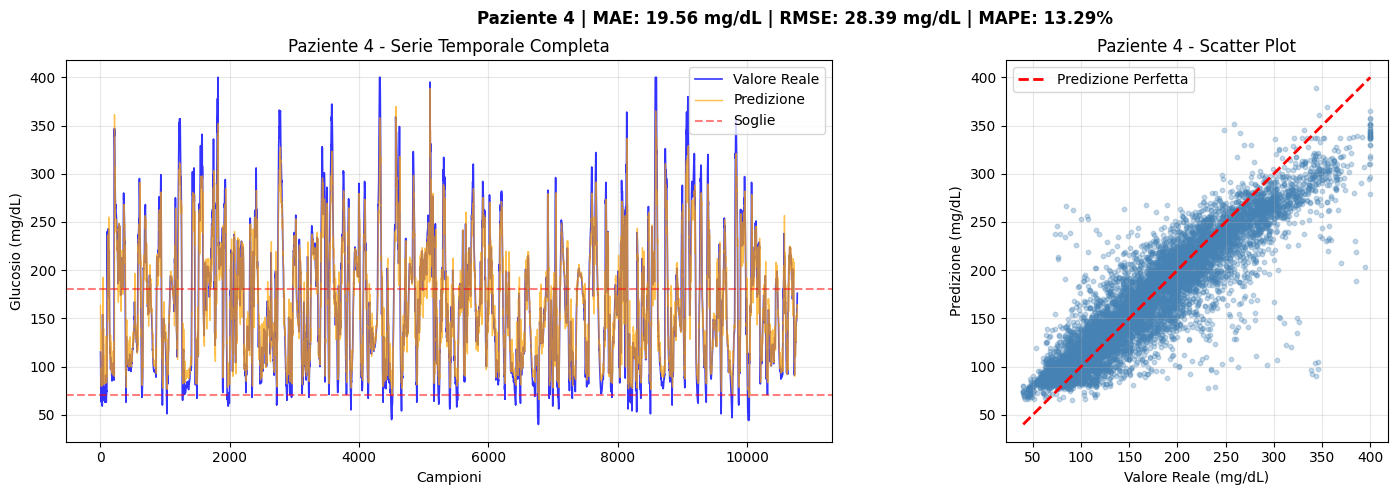

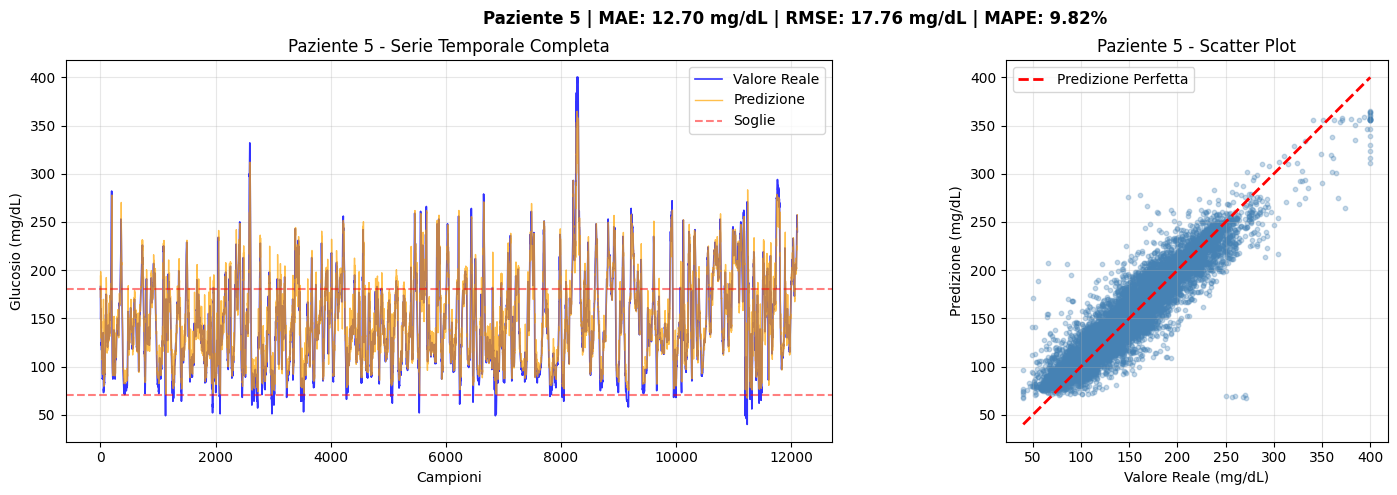

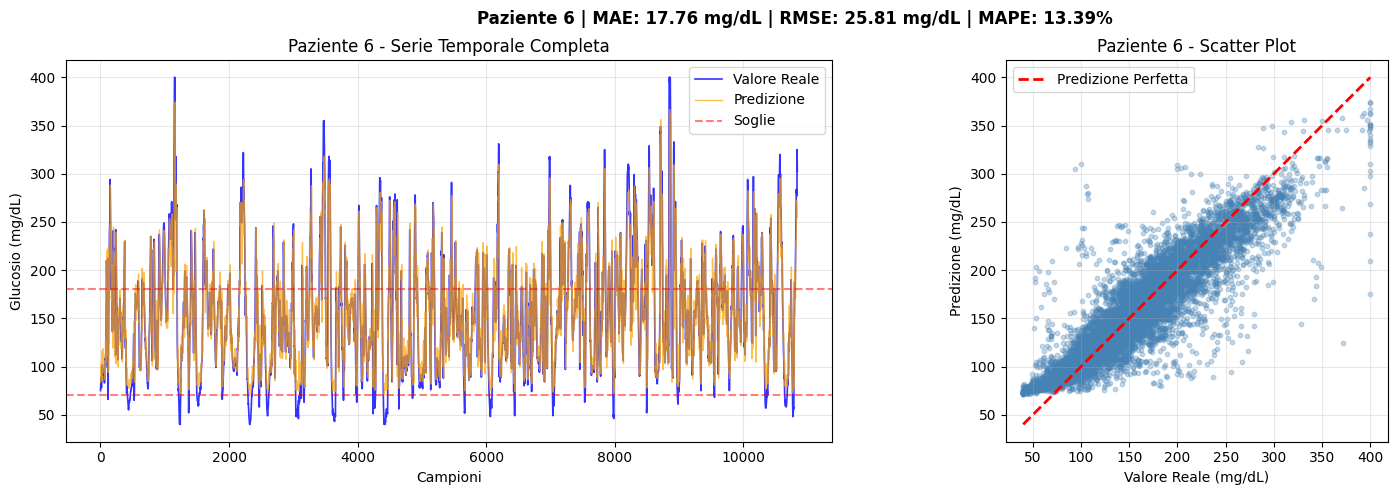

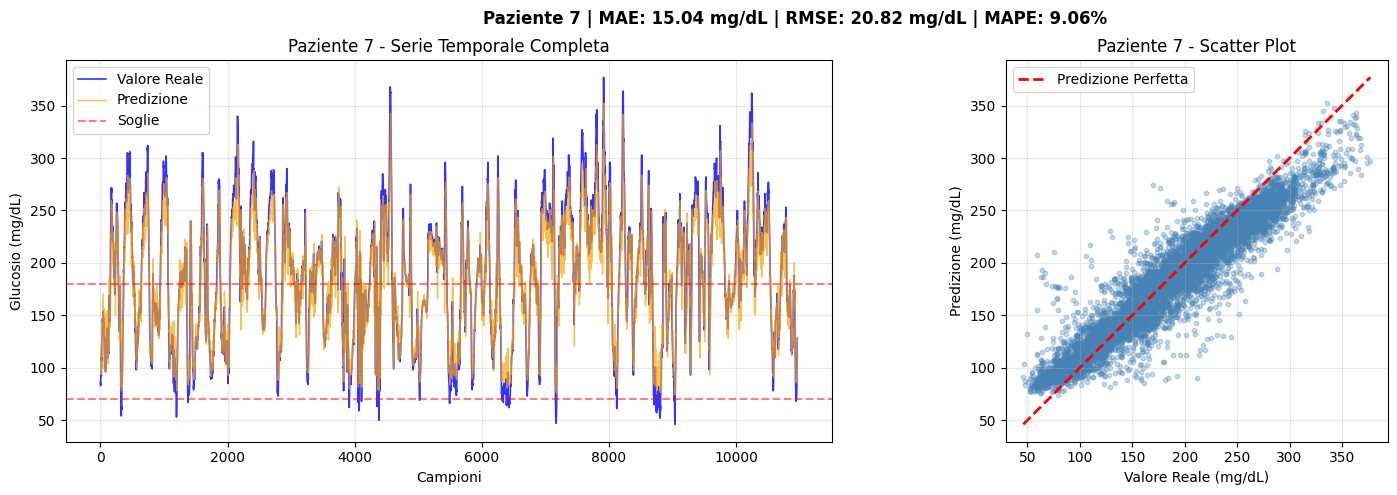

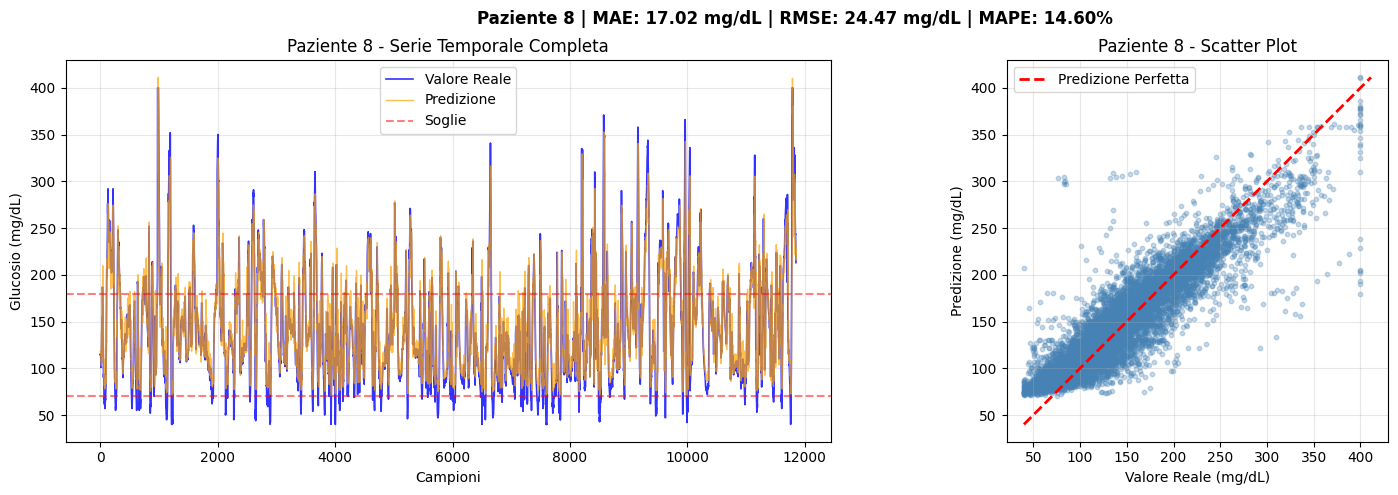

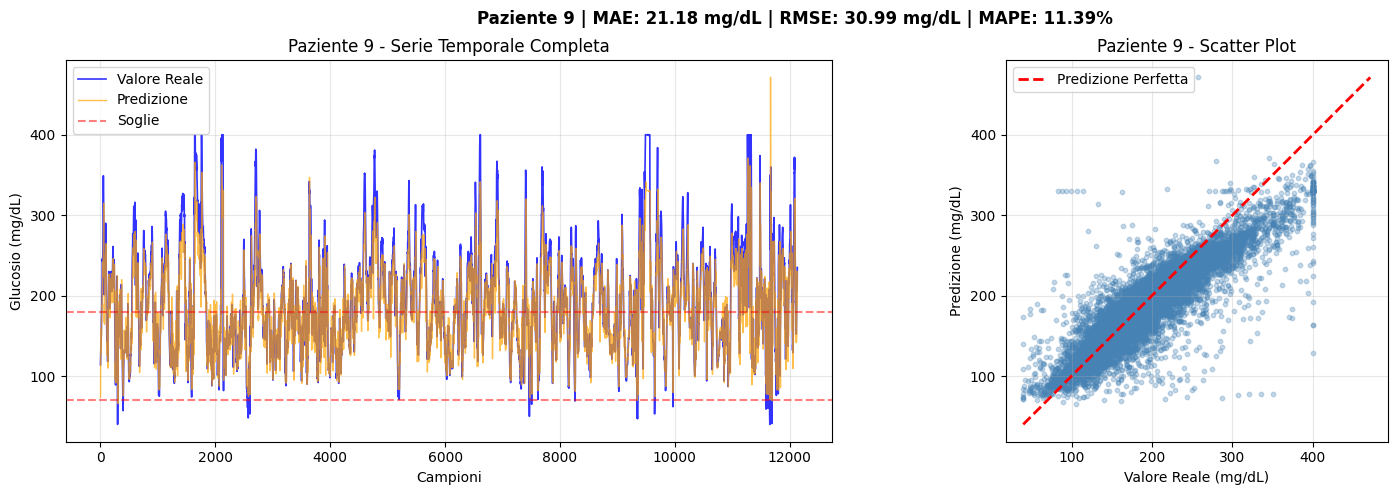

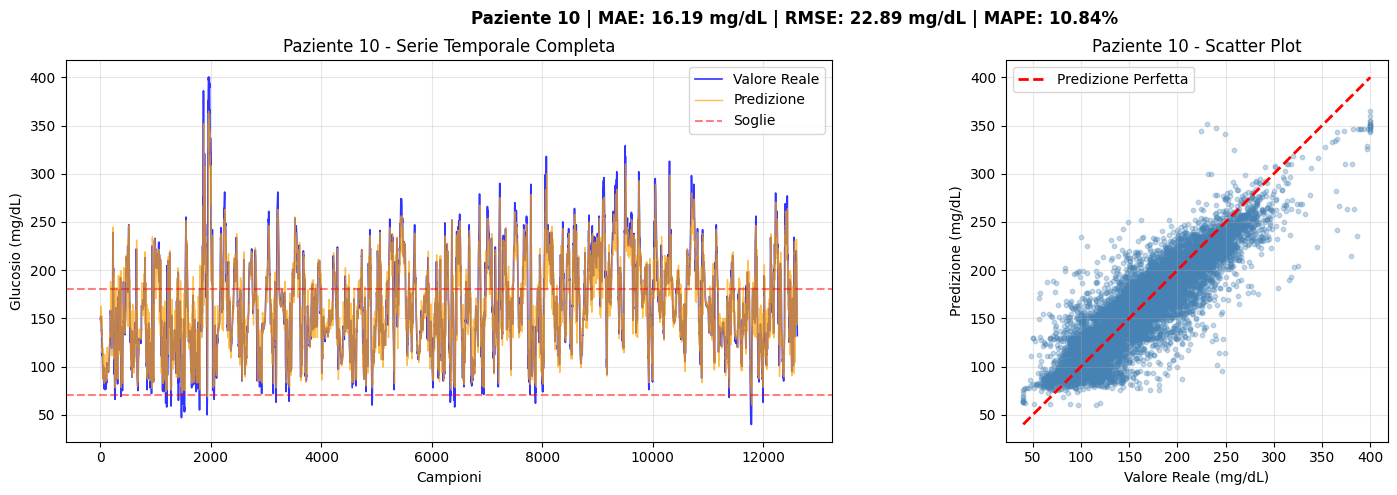

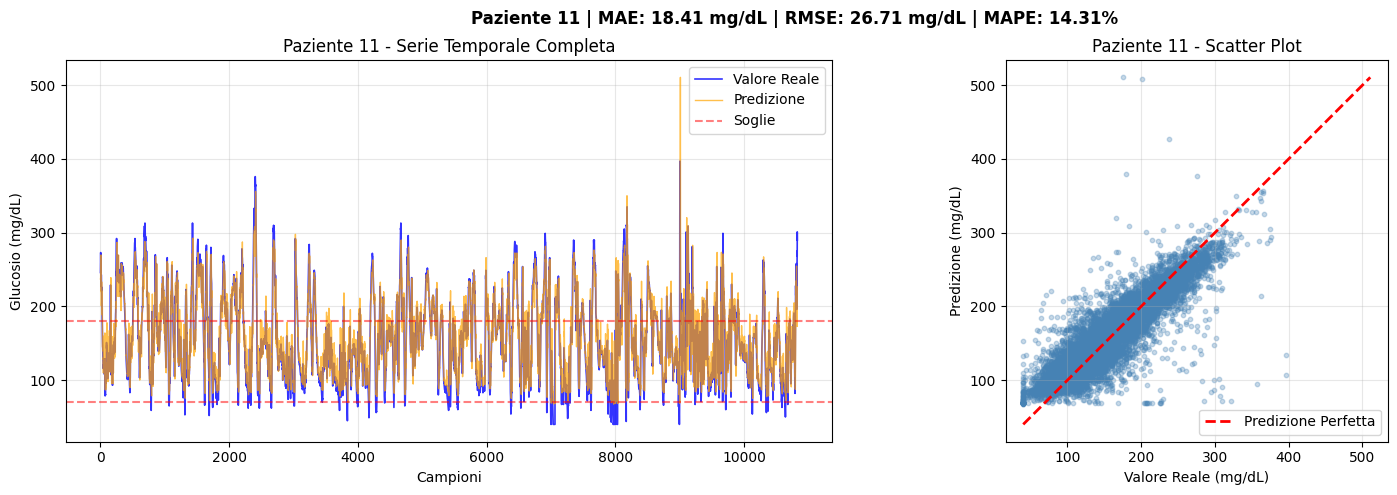

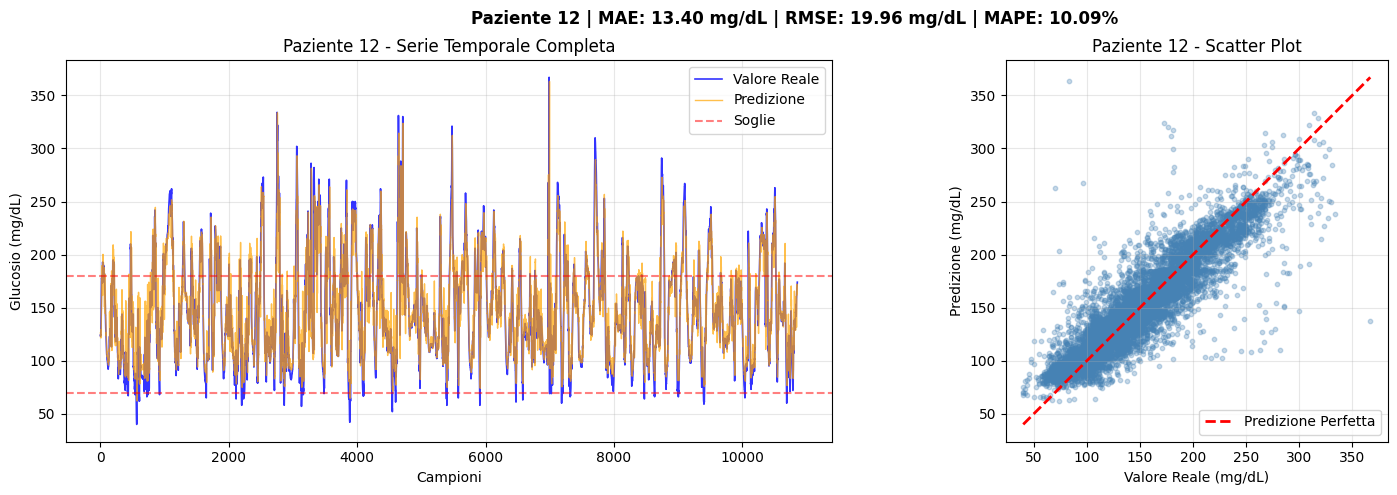

| MEDIA      | 16.78          | 23.76          | 12.20          |
| STD        | 2.40           | 3.63           | 2.35           |


In [18]:
# %% ===== 17. TABELLA RIASSUNTIVA FINALE =====
print("\n" + "="*80)
print("TABELLA RIASSUNTIVA HYPERPARAMETER TUNING - WINDOW SIZE")
print("="*80)

print(f"\n| {'PH (min)':<10} | {'MAE (mg/dL)':<18} | {'RMSE (mg/dL)':<18} | {'MAPE (%)':<18} |")
print(f"|{'-'*12}|{'-'*20}|{'-'*20}|{'-'*20}|")

for r in all_hp_results:
    marker = " *RIF.*" if r['prediction_horizon'] == PH_FIXED else ""
    print(f"| {str(r['ph_minutes']) + marker:<10} | "
          f"{r['mae_mean']:.2f} ± {r['mae_std']:.2f}        | "
          f"{r['rmse_mean']:.2f} ± {r['rmse_std']:.2f}        | "
          f"{r['mape_mean']:.2f} ± {r['mape_std']:.2f}        |")

print(f"|{'-'*12}|{'-'*20}|{'-'*20}|{'-'*20}|")

print(f"\nIperparametro ottimizzato: WINDOW SIZE")
print(f"Valori testati: {[w*5 for w in WINDOW_SIZES]} minuti")
print(f"Miglior valore: WIN = {WIN_SIZE*5} minuti")

# Risultati per paziente (PH di riferimento)
print("\n" + "="*80)
print(f"RISULTATI PER PAZIENTE - PREDICTION HORIZON = {PH_FIXED*5} minuti")
print("="*80)

patient_data = all_patient_results[PH_FIXED]

print(f"\n| {'Paziente':<10} | {'MAE (mg/dL)':<14} | {'RMSE (mg/dL)':<14} | {'MAPE (%)':<14} |")
print(f"|{'-'*12}|{'-'*16}|{'-'*16}|{'-'*16}|")

for p in patient_data:
    print(f"| {p['patient_id']:<10} | {p['mae']:<14.2f} | {p['rmse']:<14.2f} | {p['mape']:<14.2f} |")

print(f"|{'-'*12}|{'-'*16}|{'-'*16}|{'-'*16}|")

mae_list = [p['mae'] for p in patient_data]
rmse_list = [p['rmse'] for p in patient_data]# %% ===== 16. GRAFICI INDIVIDUALI PER PAZIENTE (PH di riferimento) =====
print("\n" + "="*70)
print("GRAFICI INDIVIDUALI DETTAGLIATI")
print("="*70)

for patient_result in all_patient_results[PH_FIXED]:
    y_true = patient_result['y_true']
    y_pred = patient_result['y_pred']
    patient_id = patient_result['patient_id']

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    ax1 = axes[0]
    ax1.plot(y_true, label='Valore Reale', linewidth=1.2, color='blue', alpha=0.8)
    ax1.plot(y_pred, label='Predizione', linewidth=1, color='orange', alpha=0.7)
    ax1.axhline(y=70, color='red', linestyle='--', alpha=0.5, label='Soglie')
    ax1.axhline(y=180, color='red', linestyle='--', alpha=0.5)
    ax1.set_xlabel('Campioni')
    ax1.set_ylabel('Glucosio (mg/dL)')
    ax1.set_title(f'Paziente {patient_id} - Serie Temporale Completa')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2 = axes[1]
    ax2.scatter(y_true, y_pred, alpha=0.3, s=10, color='steelblue')
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax2.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Predizione Perfetta')
    ax2.set_xlabel('Valore Reale (mg/dL)')
    ax2.set_ylabel('Predizione (mg/dL)')
    ax2.set_title(f'Paziente {patient_id} - Scatter Plot')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_aspect('equal', adjustable='box')

    plt.suptitle(f'Paziente {patient_id} | MAE: {patient_result["mae"]:.2f} mg/dL | '
                 f'RMSE: {patient_result["rmse"]:.2f} mg/dL | MAPE: {patient_result["mape"]:.2f}%',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.show()



mape_list = [p['mape'] for p in patient_data]

print(f"| {'MEDIA':<10} | {np.mean(mae_list):<14.2f} | {np.mean(rmse_list):<14.2f} | {np.mean(mape_list):<14.2f} |")
print(f"| {'STD':<10} | {np.std(mae_list):<14.2f} | {np.std(rmse_list):<14.2f} | {np.std(mape_list):<14.2f} |")




In [19]:
# %% ===== 18. RIEPILOGO CONFIGURAZIONE =====
print("\n" + "="*80)
print("CONFIGURAZIONE MODELLO")
print("="*80)

print(f"""
Modello: MLP (Multi-Layer Perceptron)
Architettura: 128 → 64 → 32 → 16 → 1 (ReLU, BatchNorm, Dropout 0.3/0.2/0.1)

Parametri Training:
  - Window Size: {WIN_SIZE} campioni ({WIN_SIZE*5} minuti) [OTTIMIZZATO su validation]
  - Prediction Horizon di riferimento: {PH_FIXED} campioni ({PH_FIXED*5} minuti)
  - Epochs: {EPOCHS}
  - Batch Size: {BATCH_SIZE}
  - Learning Rate: {LEARNING_RATE}
  - Early Stopping: patience=10, ReduceLROnPlateau: patience=5

Pulizia dati: valori fuori da {GLU_MIN}-{GLU_MAX} mg/dL -> NaN; interpolazione lineare buchi <= {MAX_GAP} campioni;
              finestre con NaN residui scartate
Validation Strategy: Leave-One-Patient-Out ({N_FOLDS} fold), validation cronologica interna (ultimo {int(VAL_FRACTION*100)}%)

PERFORMANCE FINALI @ PH={PH_FIXED*5} min (Mean ± Std):
  - MAE:  {np.mean(mae_list):.2f} ± {np.std(mae_list):.2f} mg/dL
  - RMSE: {np.mean(rmse_list):.2f} ± {np.std(rmse_list):.2f} mg/dL
  - MAPE: {np.mean(mape_list):.2f} ± {np.std(mape_list):.2f} %
  - Baseline naive RMSE: {best_result['naive_rmse_mean']:.2f} mg/dL
""")


CONFIGURAZIONE MODELLO

Modello: MLP (Multi-Layer Perceptron)
Architettura: 128 → 64 → 32 → 16 → 1 (ReLU, BatchNorm, Dropout 0.3/0.2/0.1)

Parametri Training:
  - Window Size: 12 campioni (60 minuti) [OTTIMIZZATO su validation]
  - Prediction Horizon di riferimento: 6 campioni (30 minuti)
  - Epochs: 100
  - Batch Size: 32
  - Learning Rate: 0.001
  - Early Stopping: patience=10, ReduceLROnPlateau: patience=5

Pulizia dati: valori fuori da 40-400 mg/dL -> NaN; interpolazione lineare buchi <= 12 campioni;
              finestre con NaN residui scartate
Validation Strategy: Leave-One-Patient-Out (12 fold), validation cronologica interna (ultimo 15%)

PERFORMANCE FINALI @ PH=30 min (Mean ± Std):
  - MAE:  16.78 ± 2.40 mg/dL
  - RMSE: 23.76 ± 3.63 mg/dL
  - MAPE: 12.20 ± 2.35 %
  - Baseline naive RMSE: 26.65 mg/dL

